# 02 · Baseline captioning and decoding strategies (Milestone 2)

1. Train CLIP → GPT-2 with prefix conditioning (`configs/prefix_frozen.yaml`)
2. Read the training log and the captions written after every epoch
3. Compare greedy, beam search and nucleus sampling on 10 test images, and over the whole test split

Train on a GPU (the HPC cluster). Check first with `--overfit-batch` and `--debug`.

In [1]:
# Run from the repo root (works whether Jupyter starts in notebooks/ or the root).
import warnings; warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import json, torch, transformers
print("torch", torch.__version__, "| transformers", transformers.__version__, "| CUDA", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch 2.15.0+cpu | transformers 4.57.6 | CUDA False


## Train

Run these in a terminal, or uncomment them here. The first two take a minute and catch most bugs.

In [2]:
# !python -m src.train --config configs/prefix_frozen.yaml --overfit-batch   # loss should approach 0
# !python -m src.train --config configs/prefix_frozen.yaml --debug           # whole pipeline, 3 steps
# !python -m src.train --config configs/prefix_frozen.yaml                   # full run
RUN = Path('runs/prefix_frozen')
events = [json.loads(l) for l in (RUN / 'train_log.jsonl').read_text(encoding='utf-8').splitlines()]
start = next(e for e in events if e['event'] == 'start')
{k: start[k] for k in ('device', 'injection', 'finetune', 'train_images', 'trainable', 'total', 'trainable_pct')}

{'device': 'cuda',
 'injection': 'prefix',
 'finetune': 'prefix',
 'train_images': 4000,
 'trainable': 31468800,
 'total': 155908608,
 'trainable_pct': 20.184}

## Training log

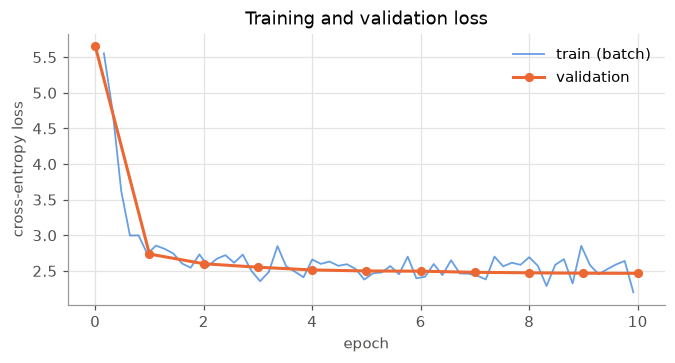

[(0, 5.658, None, None),
 (1, 2.737, 5.4, 3.17415189743042),
 (2, 2.601, 5.1, 3.17415189743042),
 (3, 2.552, 5.1, 3.17415189743042),
 (4, 2.514, 5.1, 3.17415189743042),
 (5, 2.5, 5.1, 3.17415189743042),
 (6, 2.496, 5.1, 3.17415189743042),
 (7, 2.481, 5.1, 3.17415189743042),
 (8, 2.474, 5.2, 3.17415189743042),
 (9, 2.468, 5.2, 3.17415189743042),
 (10, 2.466, 5.3, 3.17415189743042)]

In [3]:
import matplotlib.pyplot as plt
# Fixed categorical order (validated reference palette); recessive grid, no top/right spines.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=SERIES), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.8, "axes.edgecolor": "#9a9893", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
                     "figure.dpi": 110, "font.size": 10})

train = [e for e in events if e['event'] == 'train']
val = [e for e in events if e['event'] == 'val']
spe = start['steps_per_epoch']
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot([e['step'] / spe for e in train], [e['loss'] for e in train], color=SERIES[0], linewidth=1.2, alpha=0.7, label='train (batch)')
ax.plot([e['epoch'] for e in val], [e['val_loss'] for e in val], color=SERIES[1], marker='o', markersize=5, label='validation')
ax.set(xlabel='epoch', ylabel='cross-entropy loss', title='Training and validation loss')
ax.legend(frameon=False); plt.show()
[(e['epoch'], round(e['val_loss'], 3), e.get('epoch_time_s'), e.get('peak_mem_gb')) for e in val]

## Captions written after each epoch

The same validation images are captioned after every epoch, so you can watch the model learn.

In [4]:
previews = [e for e in events if e['event'] == 'preview']
for iid in dict.fromkeys(p['image_id'] for p in previews):
    rows = [p for p in previews if p['image_id'] == iid]
    print(f'image {iid} | REF: {rows[0]["reference"]}')
    for p in rows:
        print(f'  epoch {p["epoch"]:>2}: {p["generated"]}')

image 161978 | REF: Different people are doing skateboard tricks and riding.
  epoch  0: The U.S. is the only country in the world that has a "no-fly" zone in the South China Sea. The U.S. is the only country in the world
  epoch  1: A man riding a skateboard on a skateboard.
  epoch  2: A man riding a skateboard on a skateboard.
  epoch  3: A man riding a skateboard on a skateboard.
  epoch  4: A group of people skate on a skateboard.
  epoch  5: A man riding a skateboard on a skateboard.
  epoch  6: A group of skateboarders are on a skateboard.
  epoch  7: A group of people riding a skateboard.
  epoch  8: A group of skateboarders are riding on a skateboard.
  epoch  9: A group of skateboarders are on a skateboard.
  epoch 10: A group of skateboarders are on a skateboard.
image 216296 | REF: A couple of guys with tennis rackets waiting on a ball.
  epoch  0: A new study in the Journal of the American Medical Association (JAMA) and the American College of Cardiology (ACC) has found th

## Decoding strategies

- **greedy**: highest-probability token at each step
- **beam_wK**: keep the K best partial captions; pick the best full one
- **nucleus_pP_tT**: sample from the smallest token set whose probability reaches P, after dividing logits by temperature T

The captions of all 500 test images were written on the cluster from this run's best checkpoint by
`python -m src.evaluate --runs runs/prefix_frozen --decode sweep` and saved in `results/prefix_frozen/`.
The cell below reads them back, so it needs neither the checkpoint nor a GPU; if `best.pt` is present it
regenerates the ten examples instead.

175251 REF: A toddler in the bathroom brushing his teeth.
   greedy             A little boy with a toothbrush brushing his teeth.
   beam_w3            A little boy sucking on a toothbrush.
   beam_w5            A little boy sucking on a toothbrush.
   nucleus_p0.9_t0.7  A baby sucking on a toothbrush.
   nucleus_p0.9_t1.0  A baby sucking and brushing his teeth.
307598 REF: A yellow and green train, at stop lights.
   greedy             A train is on the tracks.
   beam_w3            A train is on the tracks.
   beam_w5            A train is on the tracks.
   nucleus_p0.9_t0.7  A train with a blue and white train on the track.
   nucleus_p0.9_t1.0  A yellow and black train racing down a track.
108244 REF: A black cat with a hat on the ground.
   greedy             A cat is wearing a hat.
   beam_w3            A cat wearing a hat on a hat.
   beam_w5            A cat wearing a hat on a hat.
   nucleus_p0.9_t0.7  A cat is laying on top of a hat.
   nucleus_p0.9_t1.0  A cat holding a hat

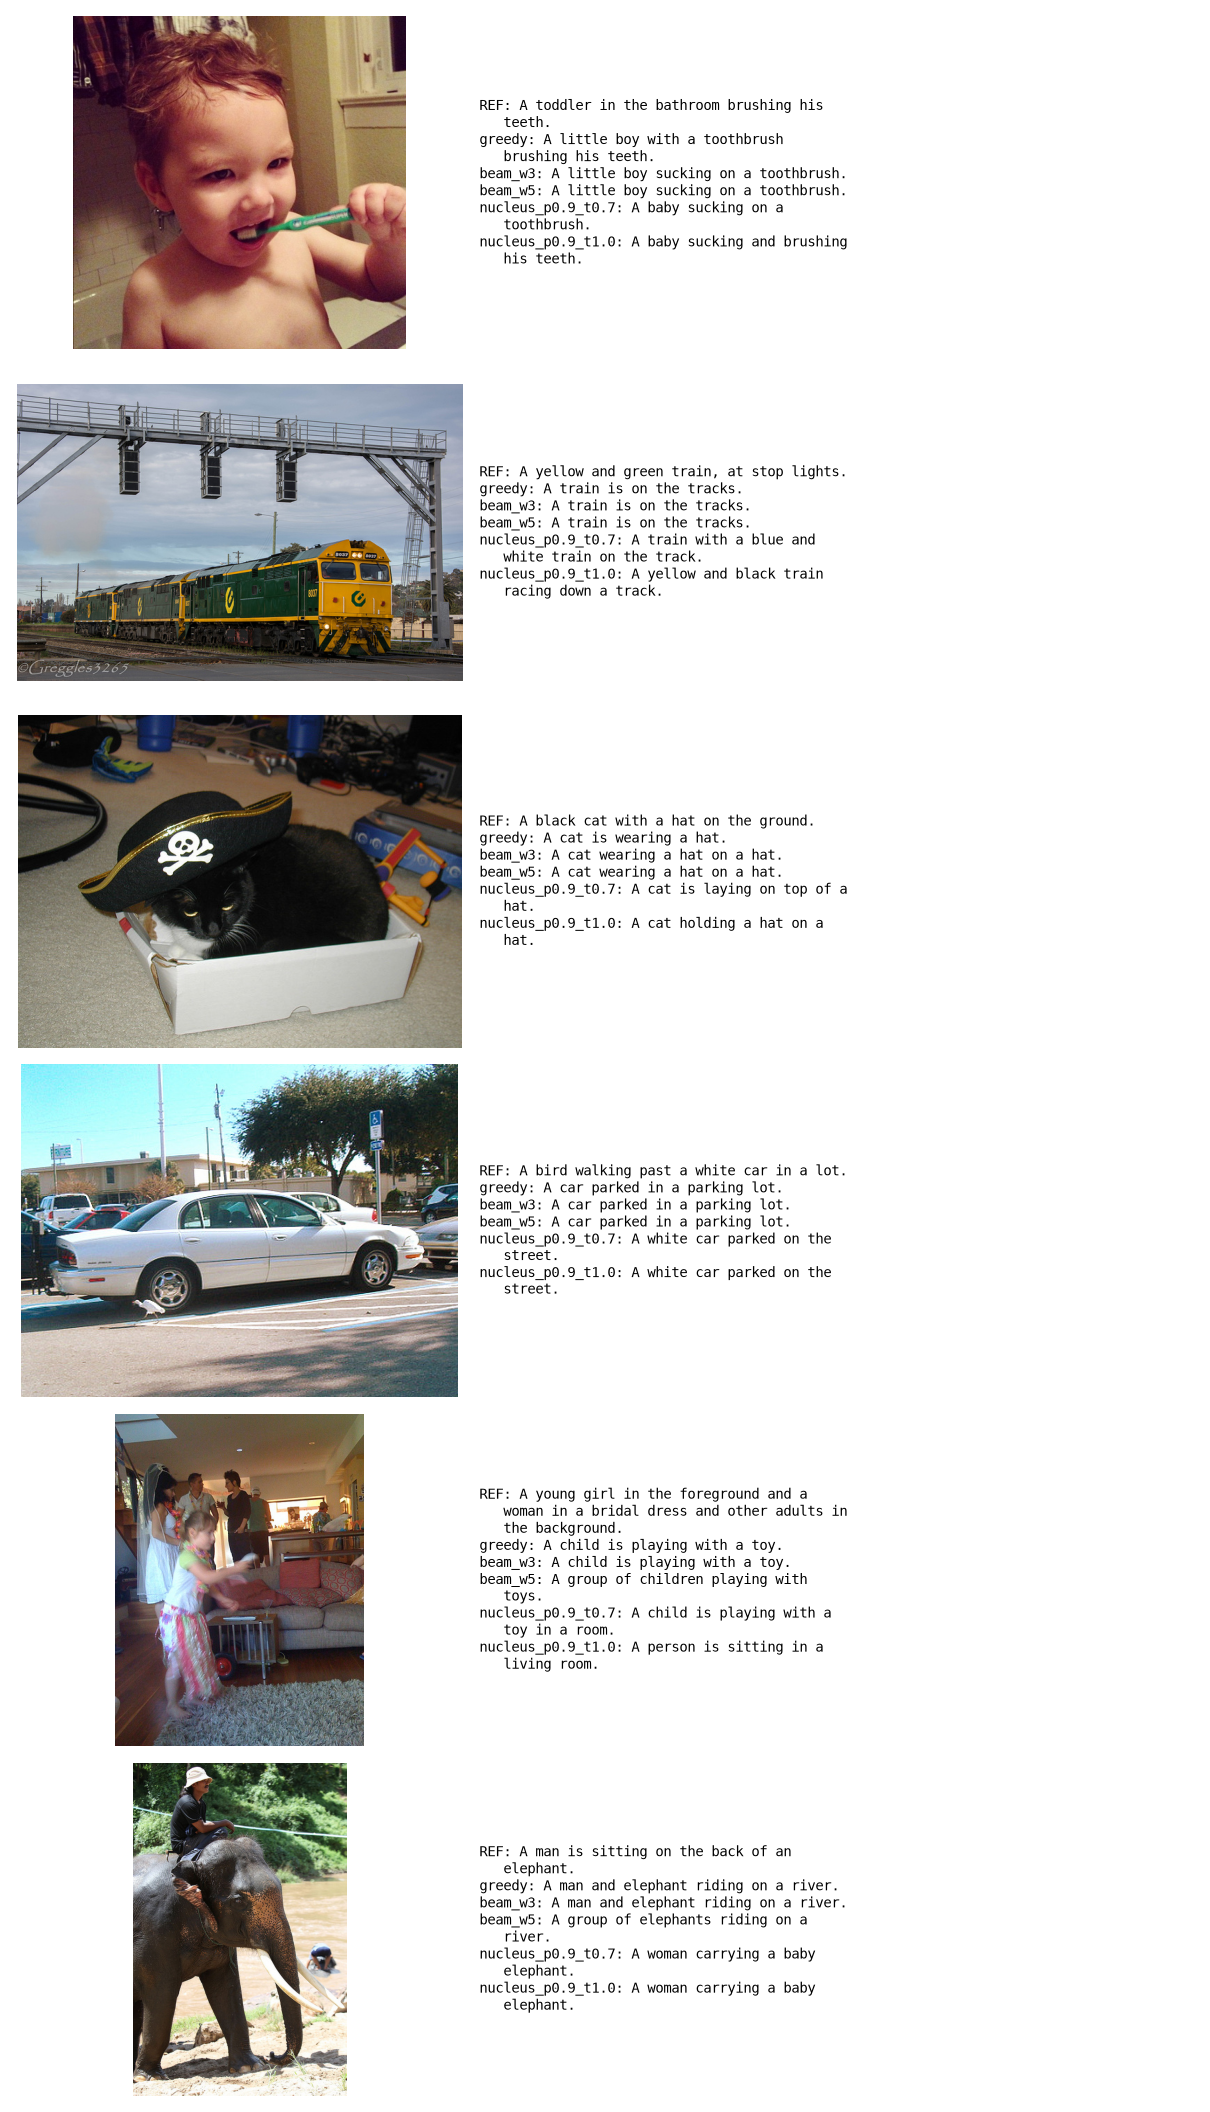

In [5]:
from IPython.display import Image as Show, display
import pandas as pd
from src import data
from src.evaluate import save_gallery

caps, splits = data.load_captions(), data.load_splits()
SPECS = ['greedy', 'beam_w3', 'beam_w5', 'nucleus_p0.9_t0.7', 'nucleus_p0.9_t1.0']
out = {s: json.loads((Path('results') / RUN.name / f'{s}_test.json').read_text(encoding='utf-8'))['captions']
       for s in SPECS}
ids10 = splits['test'][:10]

if (RUN / 'best.pt').exists():
    from src.decode import generate
    from src.model import load_run
    model, tok, cfg = load_run(RUN, DEVICE)
    emb = data.load_embeddings(cfg['clip_model'])
    key = 'pooled' if cfg['injection'] == 'prefix' else 'patch'
    feats = emb[key][[emb['index'][i] for i in ids10]].float().to(DEVICE)
    for s in SPECS:
        out[s] = {**out[s], **dict(zip(ids10, generate(model, feats, tok, s, seed=0)))}

for i in ids10:
    print(f'{i} REF: {caps[i]["captions"][0]}')
    for s in SPECS:
        print(f'   {s:<18} {out[s][i]}')
local = [i for i in ids10 if (data.IMG_DIR / caps[i]['file_name']).exists()][:6]   # images on this machine
Show(str(save_gallery(local, out, caps, Path('results/m2_decoding_samples.png'))))

### Over all 500 test images

Metrics of the same captions (`results/metrics.csv`). `distinct-2` = share of unique word pairs across all captions
(diversity); `unique` = share of images whose caption no other image got. Nucleus rows average the sampling seeds.

In [6]:
m = pd.read_csv('results/metrics.csv')
m = m[(m.name == RUN.name) & (m.split == 'test')]
cols = ['BLEU-4', 'METEOR', 'ROUGE-L', 'CIDEr', 'distinct-2', 'unique_captions']
order = ['greedy', 'beam_w3', 'beam_w5', 'beam_w10', 'nucleus_p0.9_t0.3', 'nucleus_p0.9_t0.5', 'nucleus_p0.9_t0.7',
         'nucleus_p0.9_t1.0', 'nucleus_p0.5_t1.0', 'nucleus_p0.8_t1.0', 'nucleus_p0.95_t1.0']
m.groupby('decode')[cols].mean().reindex([o for o in order if o in set(m.decode)]).round(3).rename(columns={'unique_captions': 'unique'})

,BLEU-4,METEOR,ROUGE-L,CIDEr,distinct-2,unique
decode,,,,,,
greedy,0.222,0.208,0.492,0.747,0.233,0.884
beam_w3,0.240,0.216,0.503,0.788,0.225,0.858
beam_w5,0.240,0.217,0.498,0.778,0.213,0.852
beam_w10,0.238,0.216,0.493,0.769,0.201,0.850
nucleus_p0.9_t0.3,0.221,0.210,0.490,0.738,0.249,0.924
nucleus_p0.9_t0.5,0.209,0.208,0.479,0.709,0.297,0.971
nucleus_p0.9_t0.7,0.179,0.199,0.453,0.636,0.362,0.996
nucleus_p0.9_t1.0,0.103,0.167,0.377,0.403,0.550,1.000
nucleus_p0.5_t1.0,0.189,0.200,0.464,0.653,0.342,0.988


## Observations

**Training.** Only the mapping MLP trains (31.5 M of 155.9 M parameters, 20%); GPT-2 and CLIP stay frozen.
Validation loss falls from 5.66 before training to 2.74 after one epoch and 2.47 after ten. It is still creeping
down at epoch 10 and stays close to the training loss, so the model is not overfitting yet; a longer run with early
stopping is worth trying. One epoch takes about 5 s on a V100 with 3.2 GB of GPU memory, because the CLIP features
are cached.

**Captions during training.** Before training (epoch 0) GPT-2 ignores the random prefix and writes news-like text
that has nothing to do with the image. After a single epoch it already writes short COCO-style captions that name
the main object ("A man riding a skateboard…", "A tennis player…"). Later epochs add some detail (a group of people
instead of one man) but change little after epoch 5.

**Decoding strategies** (500 test images):

- Beam search with width 3 scores best (CIDEr 0.79 against 0.75 for greedy). Wider beams do not help (0.78 at width 5,
  0.77 at width 10) and make captions less diverse: more images get the same safe caption.
- Nucleus sampling trades accuracy for diversity, and temperature controls how much. At temperature 0.3 it behaves
  like greedy (CIDEr 0.74); at 1.0 CIDEr drops to 0.40 while distinct-2 more than doubles (0.23 → 0.55) and every
  image gets its own caption. Raising top-p at temperature 1.0 has the same effect.

**Where the model fails.**

- Generic captions that miss the main subject: the bird in the parking lot becomes "A car parked in a parking lot".
- Repetition, mostly with beam search: "A cat wearing a hat on a hat", "riding a skateboard on a skateboard".
- Sampling adds details such as colours that are often wrong ("a yellow and black train").

**Next (Milestone 3):** fine-tune GPT-2 with LoRA or fully, compare prefix conditioning with cross-attention, try
no-repeat n-gram blocking against the repetitions, and score everything with BLEU, METEOR, ROUGE-L and CIDEr.